In [1]:
from pathlib import Path
import re
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap
import numpy as np
import pandas as pd

In [ ]:
DATA = Path("../Data")

cameras = pd.DataFrame(
    {
        "Site": [
            "Boquillas", "CharlestonMesquite", "Contention", "Fairbank",
            "Hereford", "Hunter", "Moson", "St.David",
        ],
        "Camera": [8, 2, 6, 1, 5, 4, 3, 7],
    }
)

SEASONS = ["CSR", "PMD", "MON", "PMR"]
SEASON_NAMES = {"CSR": "Cool-Season Recharge", "PMD": "Pre-Monsoon Dry", "MON": "Monsoon", "PMR": "Post-Monsoon Recession"}

def water_year(dates):
    return dates.dt.year + (dates.dt.month >= 10).astype(int)

def season(dates):
    month = dates.dt.month
    return np.select(
        [month.isin([12, 1, 2, 3]), month.isin([4, 5, 6]), month.isin([7, 8, 9]), month.isin([10, 11])],
        SEASONS,
        default="",
    )

def load_nagler():
    raw = pd.read_csv(DATA / "ET" / "NaglerET.csv", header=None, skiprows=7)
    site_columns = {
        "Hereford": (3, 6),
        "Hunter": (3, 12),
        "Moson": (3, 18),
        "CharlestonMesquite": (3, 24),
        "Boquillas": (3, 30),
        "Fairbank": (3, 36),
        "Contention": (54, 57),
        "St.David": (54, 63),
    }
    series_list = []
    for site, (date_col, avg_col) in site_columns.items():
        series = raw[[date_col, avg_col]].dropna().copy()
        series.columns = ["date", "ET"]
        series["date"] = pd.to_datetime(series["date"], format="mixed")
        series["ET"] = pd.to_numeric(series["ET"], errors="coerce")
        series["Site"] = site
        series_list.append(series.dropna())
    return pd.concat(series_list, ignore_index=True).merge(cameras, on="Site", validate="many_to_one")

def nagler_to_daily(data):
    """Give each day the rate (mm/day) of the nearest 16-day composite; composite dates drift between years, so no fixed grid."""
    days = pd.DataFrame({"date": pd.date_range(data["date"].min() - pd.Timedelta(days=8), data["date"].max() + pd.Timedelta(days=8))})
    return pd.concat(
        [
            pd.merge_asof(days, group.sort_values("date"), on="date", direction="nearest", tolerance=pd.Timedelta(days=12))
            for _, group in data.groupby("Camera")
        ],
        ignore_index=True,
    ).dropna(subset=["ET"])

et_composites = load_nagler().sort_values(["Camera", "date"]).reset_index(drop=True)
et_daily = nagler_to_daily(et_composites)
et_daily["Water_Year"] = water_year(et_daily["date"])
et_daily["Season"] = season(et_daily["date"])

calendar = pd.DataFrame({
    "date": pd.date_range(f"{et_daily['Water_Year'].min() - 1}-10-01", f"{et_daily['Water_Year'].max()}-09-30")
})
season_lengths = (
    calendar.assign(Water_Year=water_year(calendar["date"]), Season=season(calendar["date"]))
    .groupby(["Water_Year", "Season"]).size().rename("season_days").reset_index()
)
et_seasonal = (
    et_daily.groupby(["Camera", "Water_Year", "Season"], as_index=False)["ET"]
    .agg(ET="sum", n_days="size")
    .merge(season_lengths, on=["Water_Year", "Season"])
    .query("n_days == season_days")
)

et_climatology = (
    et_daily.assign(doy=lambda d: d["date"].dt.dayofyear)
    .query("doy <= 365")
    .groupby(["Camera", "doy"])["ET"]
    .agg(["mean", "std"])
    .reset_index()
    .assign(calendar_date=lambda d: pd.Timestamp("2001-01-01") + pd.to_timedelta(d["doy"] - 1, unit="D"))
)

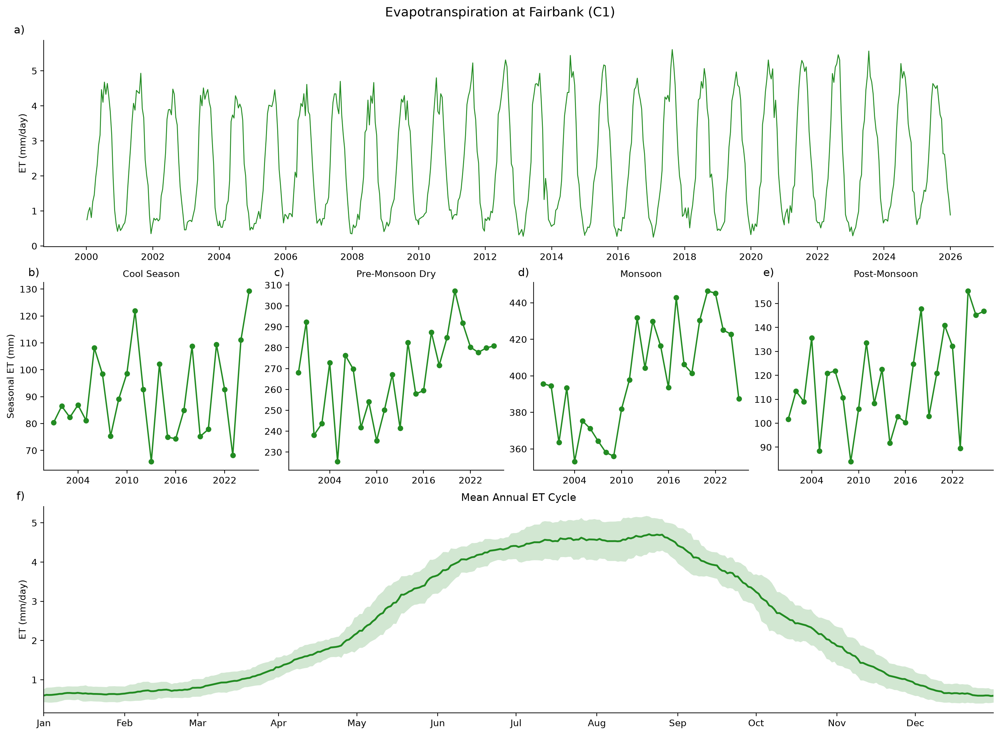

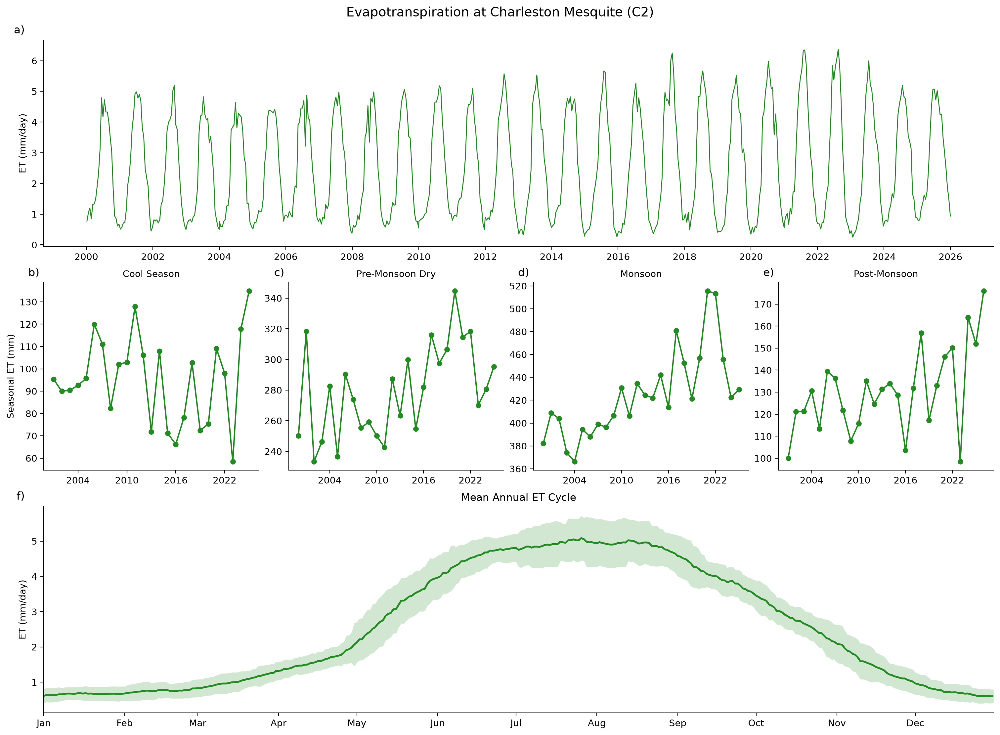

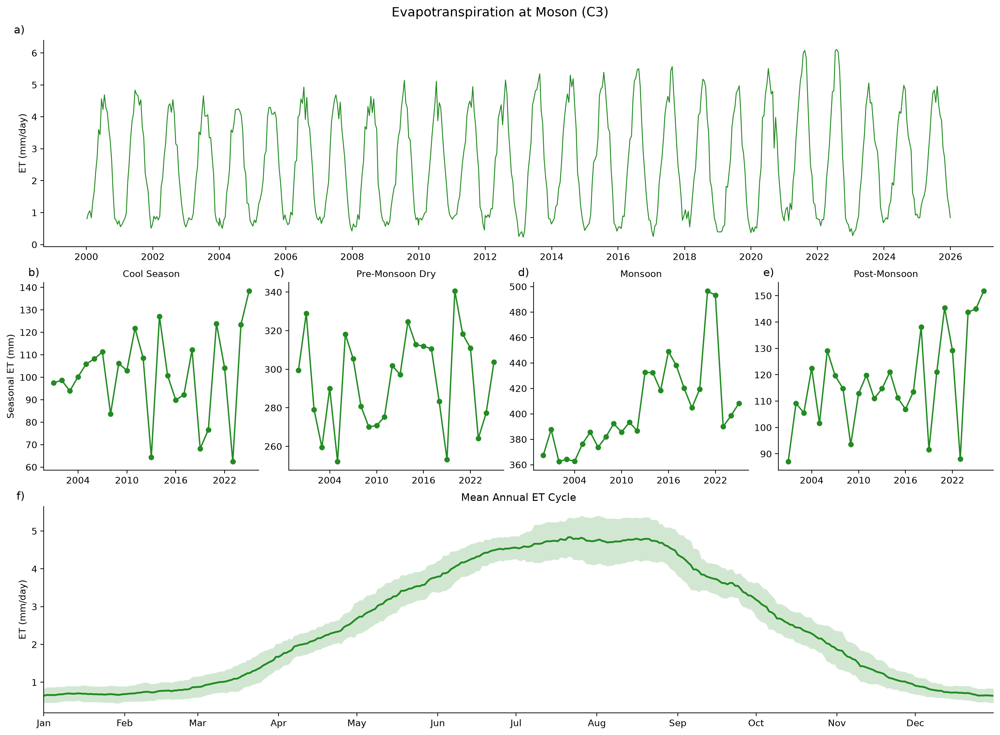

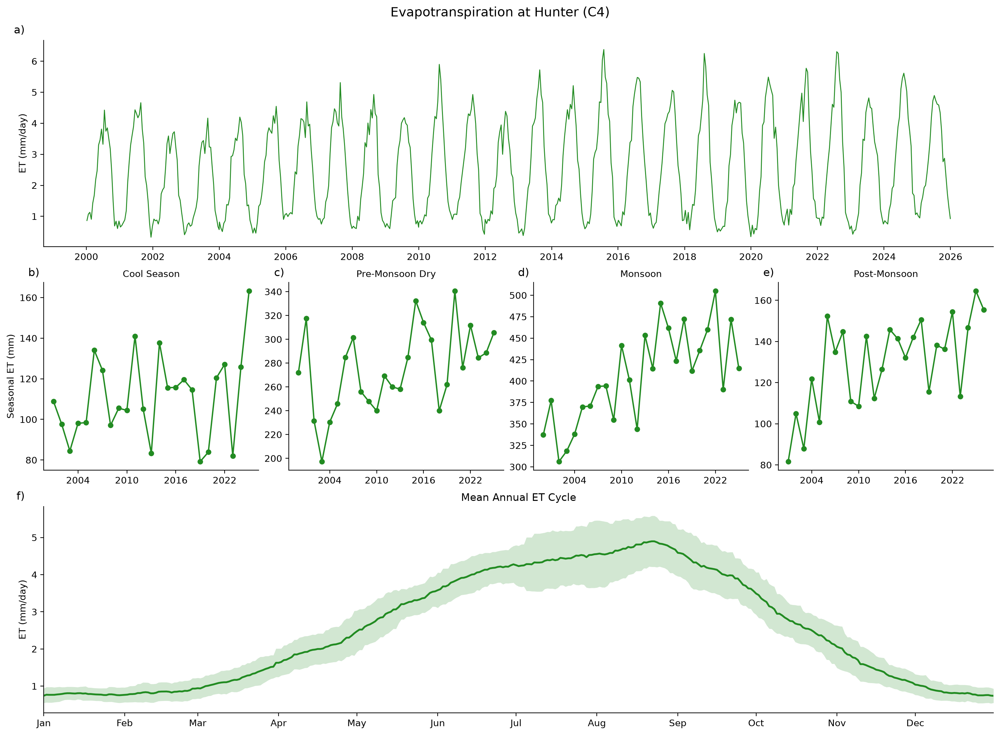

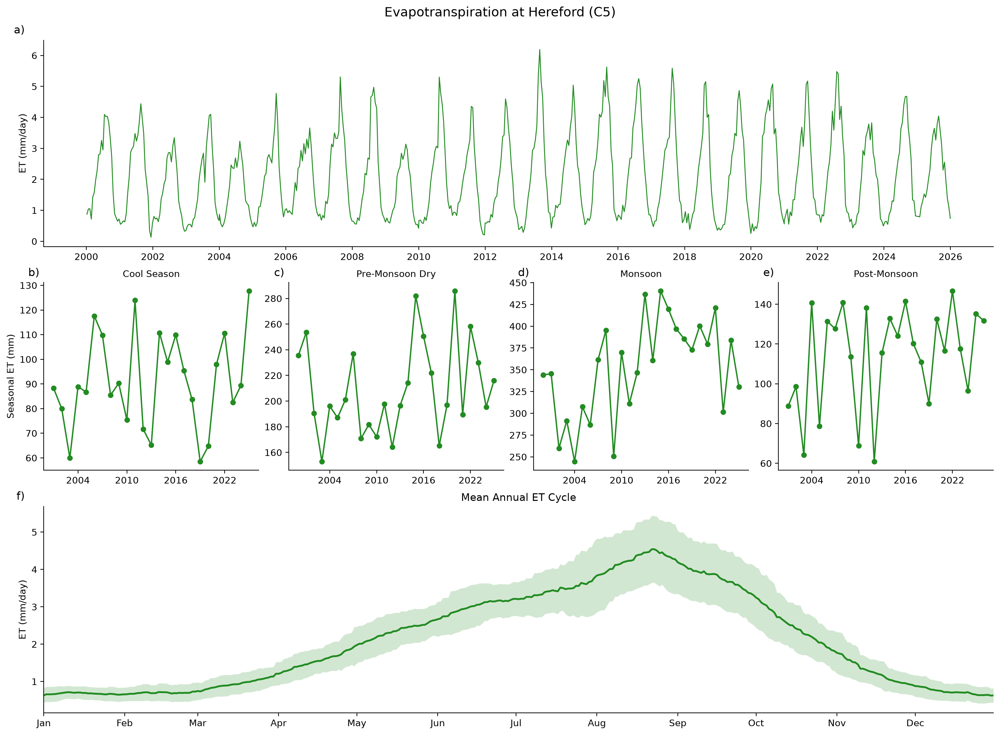

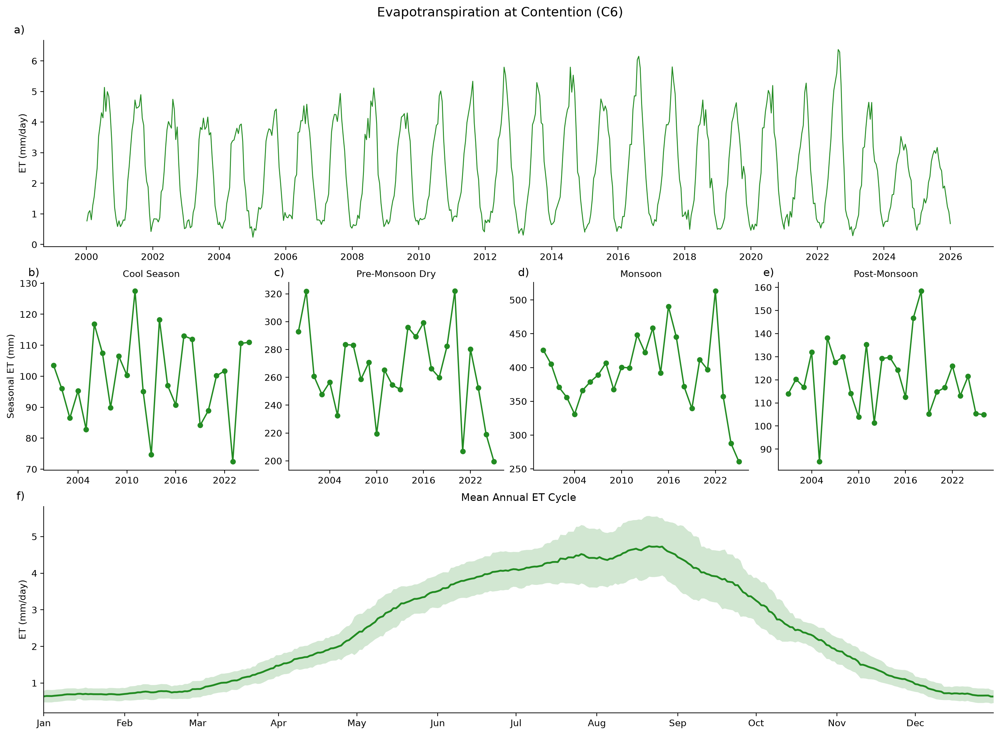

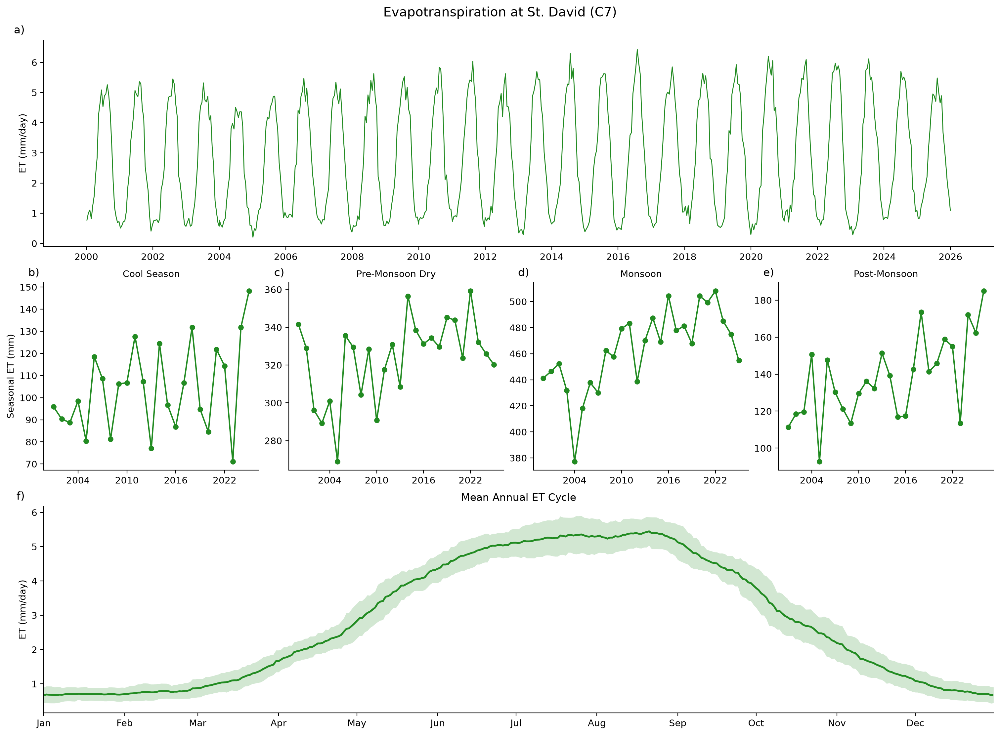

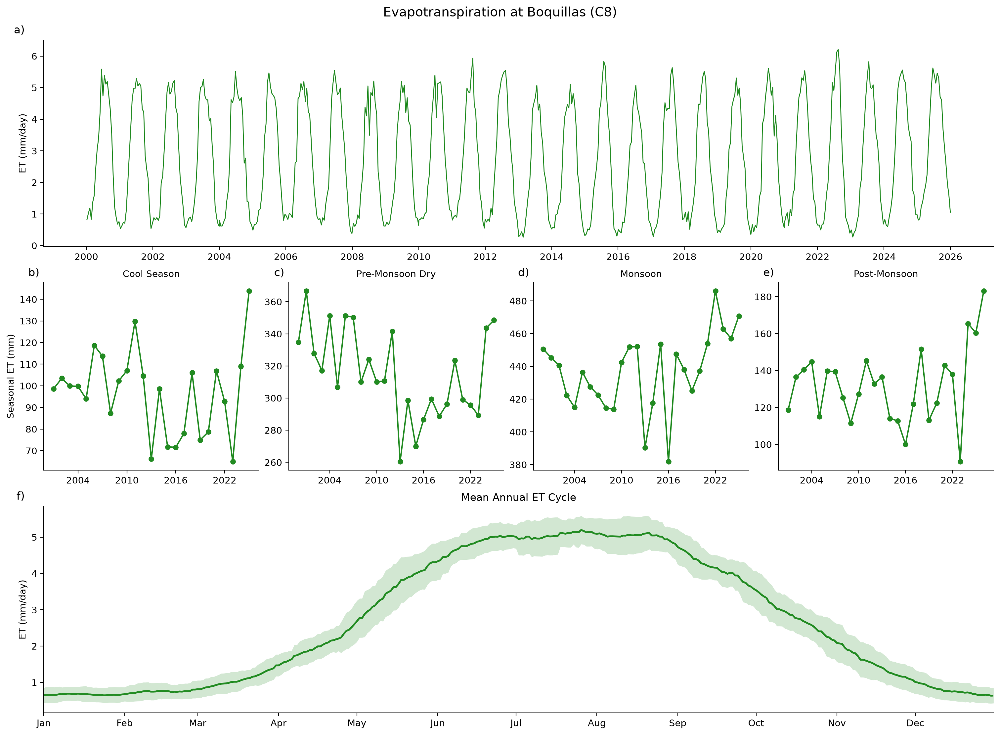

In [8]:
ET_COLOR = "forestgreen"

def site_label(camera):
    site = cameras.loc[cameras["Camera"] == camera, "Site"].iloc[0]
    return f"{re.sub(r'(?<!^)(?=[A-Z])', ' ', site)} (C{camera})"

def style(axis):
    axis.spines[["top", "right"]].set_visible(False)

for camera in sorted(cameras["Camera"]):
    composites = et_composites[et_composites["Camera"] == camera]
    seasonal = et_seasonal[et_seasonal["Camera"] == camera]
    climatology = et_climatology[et_climatology["Camera"] == camera]

    fig, axes = plt.subplot_mosaic(
        [["full"] * 4, SEASONS, ["clim"] * 4],
        figsize=(15, 11), height_ratios=[1.1, 1, 1.1], layout="constrained",
    )
    fig.suptitle(f"Evapotranspiration at {site_label(camera)}", fontsize=14)

    axis = axes["full"]
    axis.plot(composites["date"], composites["ET"], color=ET_COLOR, linewidth=1)
    axis.set_ylabel("ET (mm/day)")
    axis.xaxis.set_major_locator(mdates.YearLocator(base=2))
    axis.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    style(axis)

    for season_code in SEASONS:
        axis = axes[season_code]
        data = seasonal[seasonal["Season"] == season_code]
        axis.plot(data["Water_Year"], data["ET"], color=ET_COLOR, linewidth=1.5, marker="o", markersize=5)
        axis.set_title(SEASON_NAMES[season_code], fontsize=10)
        axis.xaxis.set_major_locator(plt.MaxNLocator(5, integer=True))
        style(axis)
    axes["CSR"].set_ylabel("Seasonal ET (mm)")

    axis = axes["clim"]
    axis.fill_between(
        climatology["calendar_date"], climatology["mean"] - climatology["std"], climatology["mean"] + climatology["std"],
        color=ET_COLOR, alpha=0.2, linewidth=0,
    )
    axis.plot(climatology["calendar_date"], climatology["mean"], color=ET_COLOR, linewidth=2)
    axis.set_title(f"Mean Annual ET Cycle", fontsize=11)
    axis.set_ylabel("ET (mm/day)")
    axis.xaxis.set_major_locator(mdates.MonthLocator())
    axis.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    axis.set_xlim(pd.Timestamp("2001-01-01"), pd.Timestamp("2001-12-31"))
    style(axis)

    for letter, key in zip("abcdef", ["full"] + SEASONS + ["clim"]):
        axes[key].text(-0.02, 1.02, f"{letter})", transform=axes[key].transAxes, ha="right", va="bottom", fontsize=12)

    plt.show()

%config InlineBackend.figure_format = "retina"

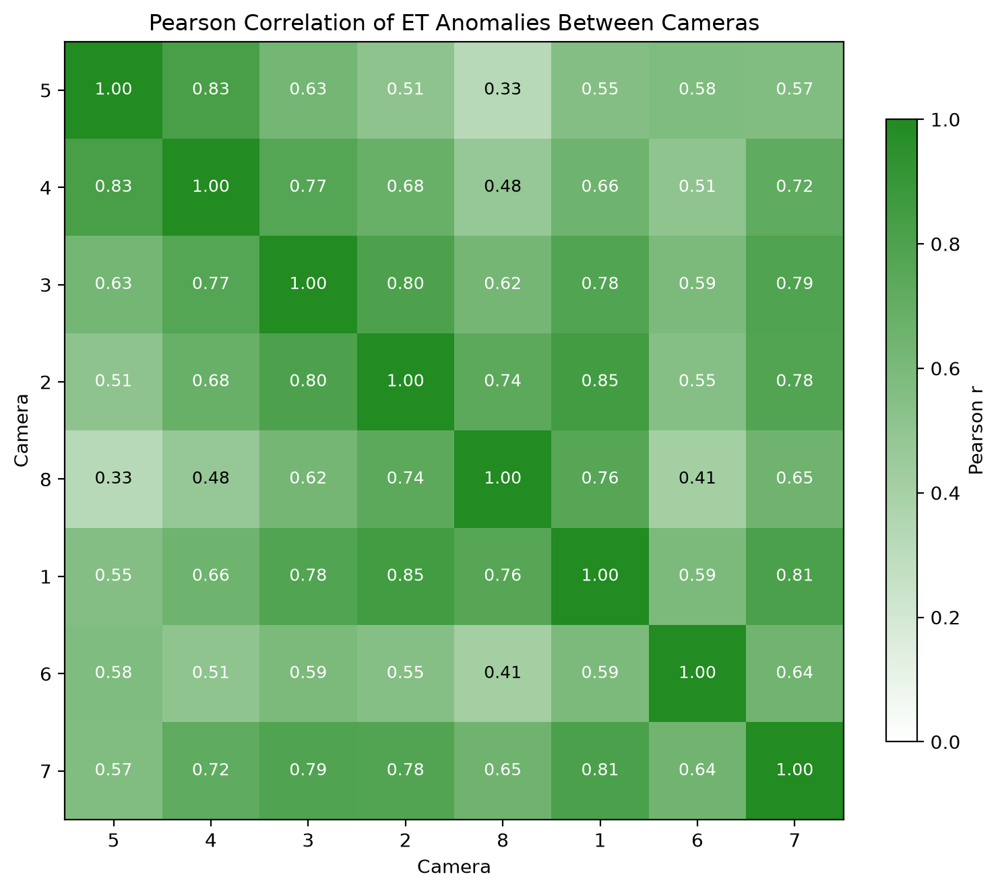

In [ ]:
camera_order = (
    pd.read_csv(DATA / "USPPFlowMonitoring2006_2025.csv", usecols=["Site", "Latitude"])
    .groupby("Site", as_index=False).first()
    .merge(cameras, on="Site")
    .sort_values("Latitude")["Camera"]
    .tolist()
)

et_wide = (
    et_composites.pivot(index="date", columns="Camera", values="ET")
    [camera_order]
    .dropna()
)
et_monthly_mean = et_wide.groupby(et_wide.index.month).transform("mean")
et_anomaly = et_wide - et_monthly_mean
et_correlation = et_anomaly.corr()

def correlation_matrix(correlation, color, title, vmin):
    """Heatmap of a camera-by-camera correlation matrix; undefined cells (constant series) are left blank."""
    cmap = LinearSegmentedColormap.from_list("white_to_color", ["white", color])
    cmap.set_bad("0.92")
    labels = [str(camera) for camera in correlation.columns]
    fig, axis = plt.subplots(figsize=(7.5, 6.5), layout="constrained")
    image = axis.imshow(correlation, cmap=cmap, vmin=vmin, vmax=1)
    for i in range(len(labels)):
        for j in range(len(labels)):
            value = correlation.iat[i, j]
            if np.isnan(value):
                continue
            text_color = "white" if value > (vmin + 1) / 2 else "black"
            axis.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=9, color=text_color)
    axis.set_xticks(range(len(labels)), labels)
    axis.set_yticks(range(len(labels)), labels)
    axis.set_xlabel("Camera")
    axis.set_ylabel("Camera")
    axis.set_title(title)
    fig.colorbar(image, ax=axis, shrink=0.8, label="Pearson r")
    return fig, axis

correlation_matrix(
    et_correlation, ET_COLOR,
    f"Pearson Correlation of ET Anomalies Between Cameras",
    vmin=0,
)

%config InlineBackend.figure_format = "retina"

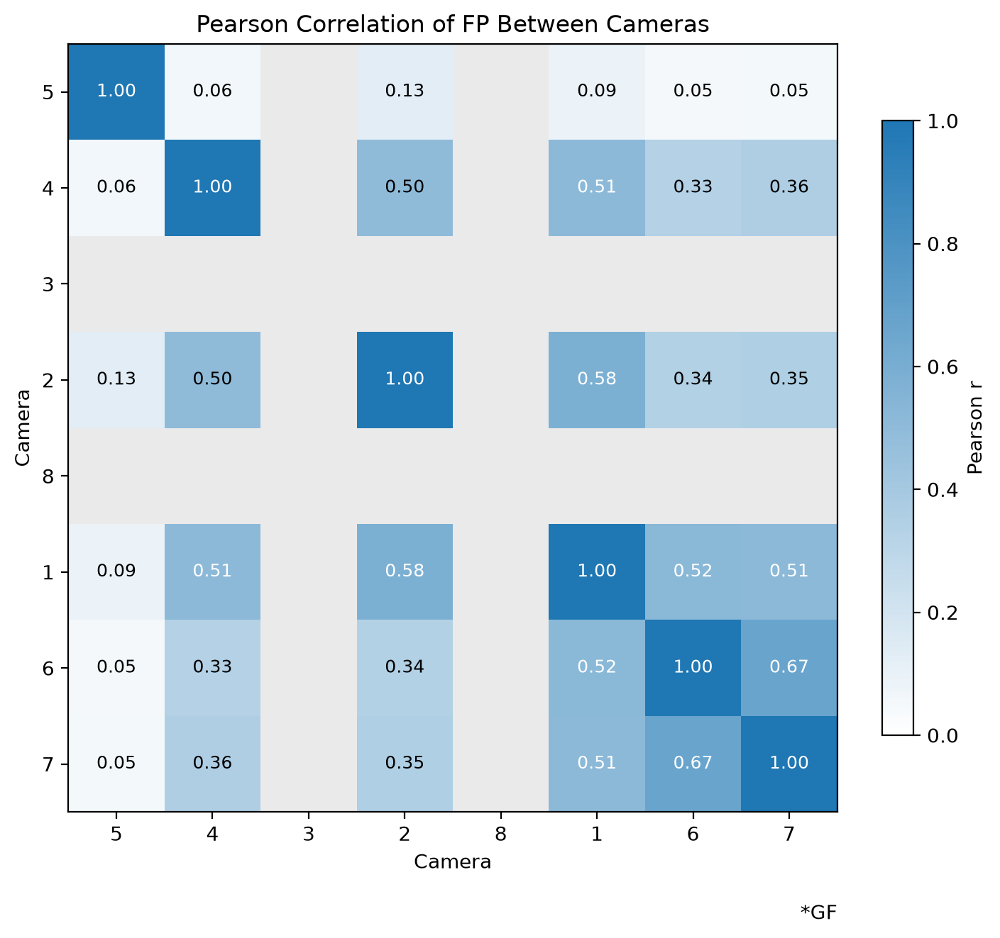

In [23]:
FP_COLOR = "tab:blue"

fp_wide = (
    pd.read_csv(DATA / "SPRNCAPredFP.csv", parse_dates=["date"])
    .rename(columns={"site": "Site"})
    .merge(cameras, on="Site", validate="many_to_one")
    .pivot(index="date", columns="Camera", values="fp_final")
    [camera_order]
    .dropna()
)
fp_correlation = fp_wide.corr()
fig, axis = correlation_matrix(
    fp_correlation, FP_COLOR,
    "Pearson Correlation of FP Between Cameras",
    vmin=0,
)
axis.text(1, -0.12, "*GF", transform=axis.transAxes, ha="right", va="top")

%config InlineBackend.figure_format = "retina"

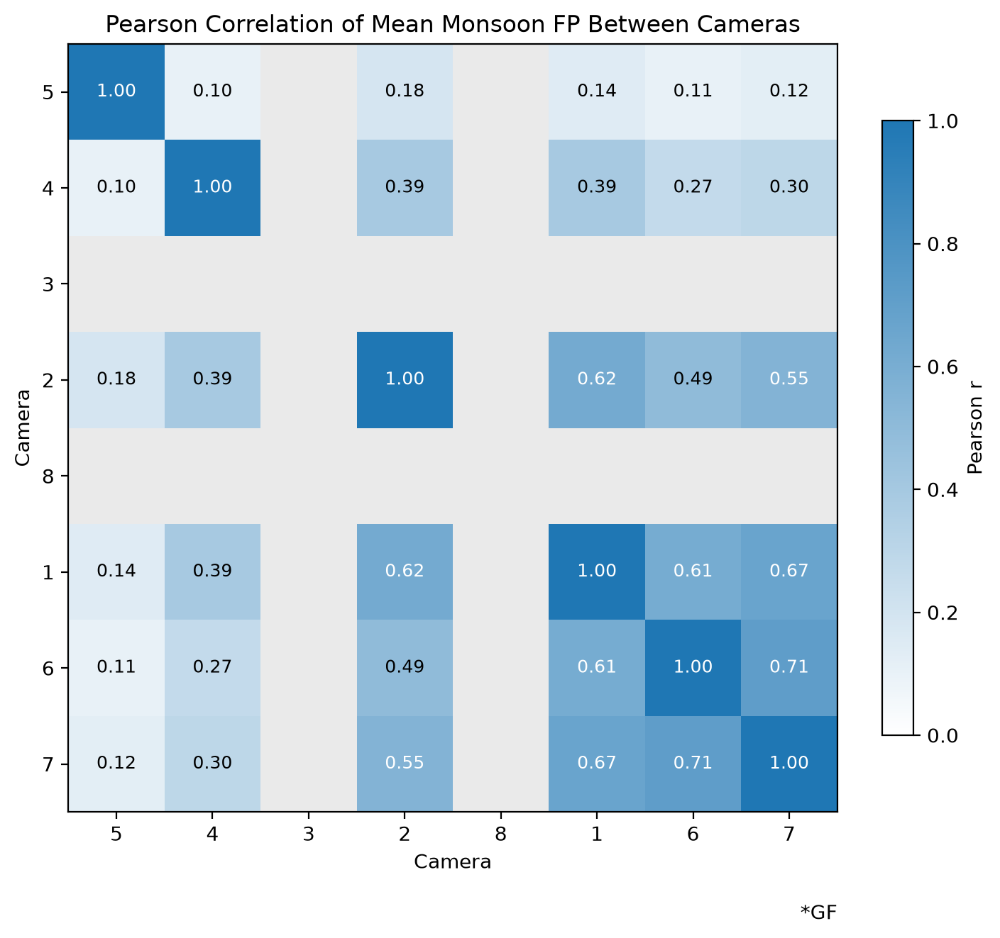

In [24]:
fp_monsoon_correlation = fp_wide[season(fp_wide.index.to_series()) == "MON"].corr()
fig, axis = correlation_matrix(
    fp_monsoon_correlation, FP_COLOR,
    "Pearson Correlation of Mean Monsoon FP Between Cameras",
    vmin=0,
)
axis.text(1, -0.12, "*GF", transform=axis.transAxes, ha="right", va="top")

%config InlineBackend.figure_format = "retina"

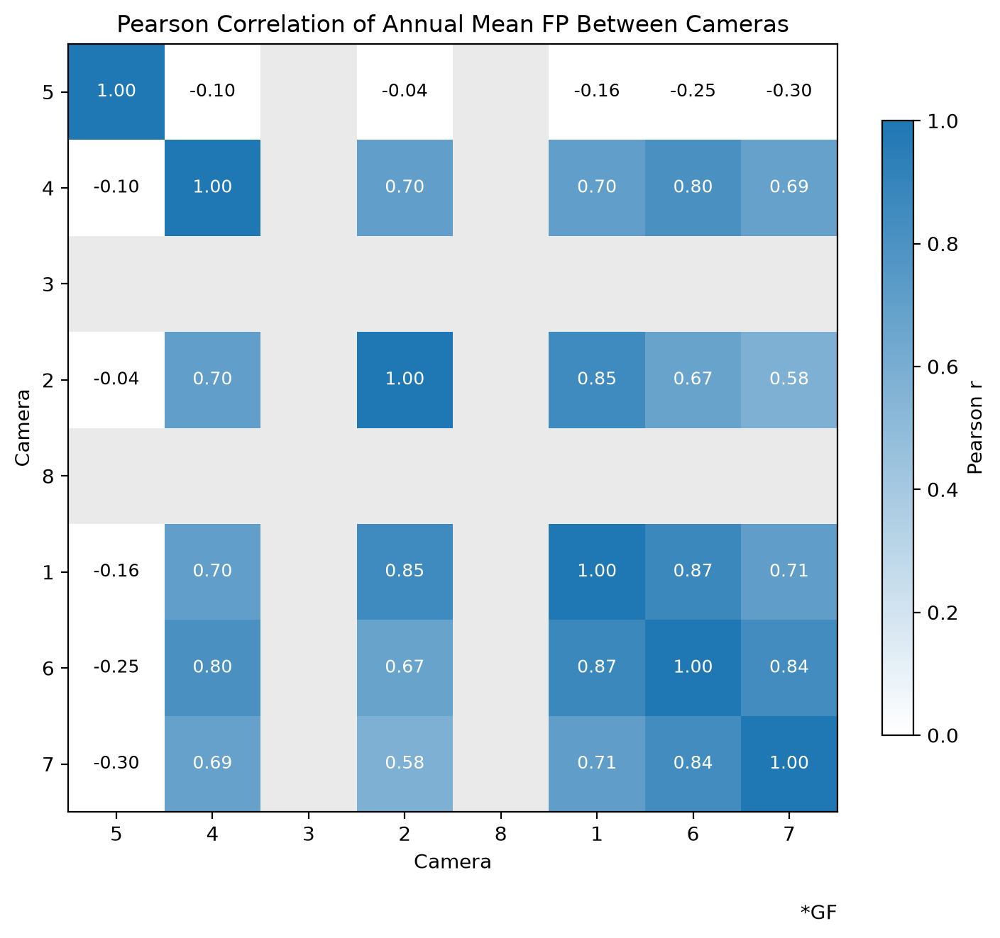

In [ ]:
fp_annual = fp_wide.groupby(water_year(fp_wide.index.to_series())).agg(["mean", "size"])
fp_annual = fp_annual.xs("mean", axis=1, level=1)[fp_annual.xs("size", axis=1, level=1).min(axis=1) >= 365]
fp_annual_correlation = fp_annual.corr()
fig, axis = correlation_matrix(
    fp_annual_correlation, FP_COLOR,
    "Pearson Correlation of Annual Mean FP Between Cameras",
    vmin=0,
)
axis.text(1, -0.12, "*GF", transform=axis.transAxes, ha="right", va="top")

%config InlineBackend.figure_format = "retina"

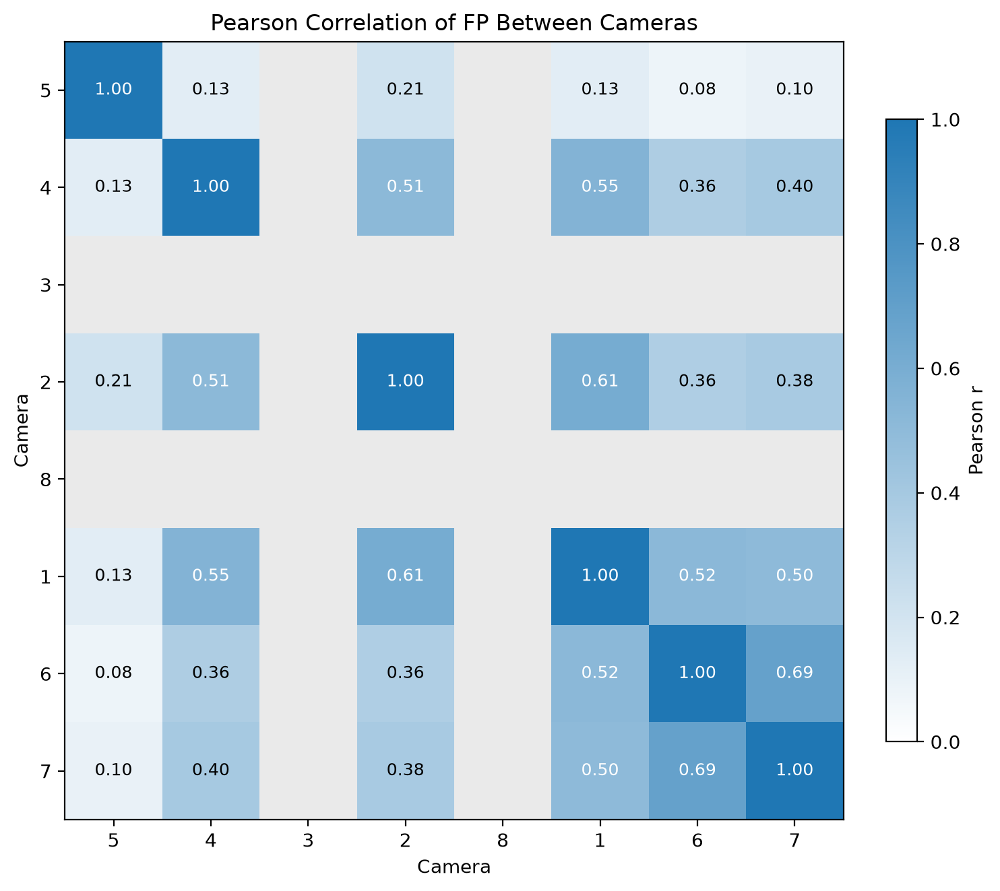

In [ ]:
observed_fp_wide = (
    pd.read_csv(DATA / "SPRNCAPredFP.csv", parse_dates=["date"])
    .rename(columns={"site": "Site"})
    .merge(cameras, on="Site", validate="many_to_one")
    .pivot(index="date", columns="Camera", values="fp")
    [camera_order]
)
observed_fp_correlation = observed_fp_wide.corr()
correlation_matrix(
    observed_fp_correlation, FP_COLOR,
    "Pearson Correlation of FP Between Cameras",
    vmin=0,
)

%config InlineBackend.figure_format = "retina"

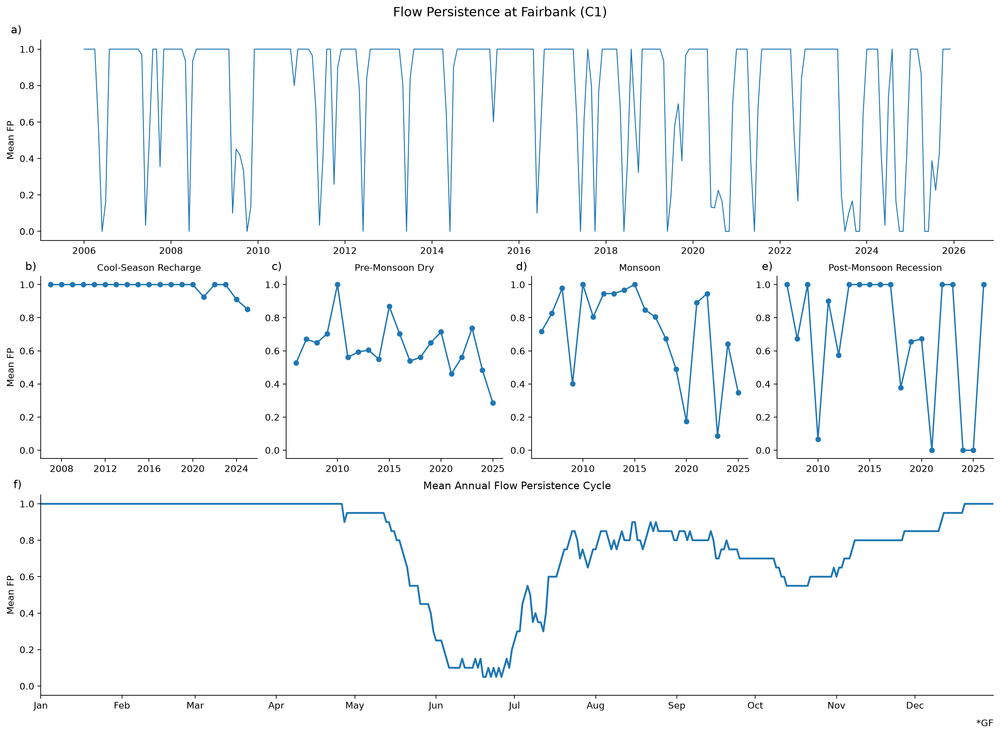

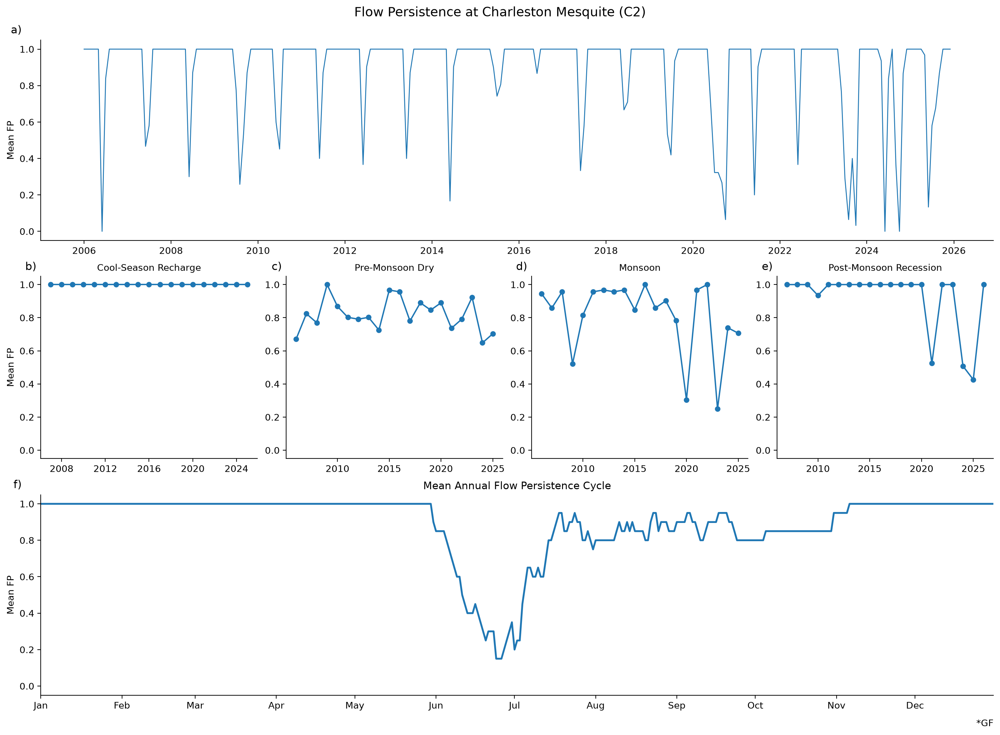

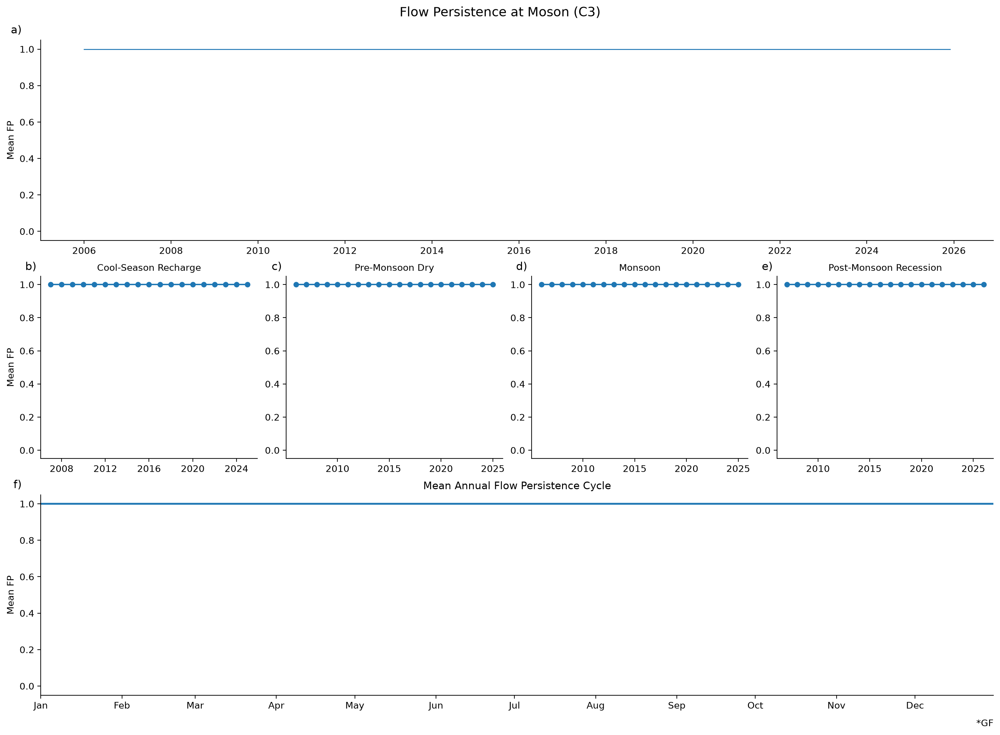

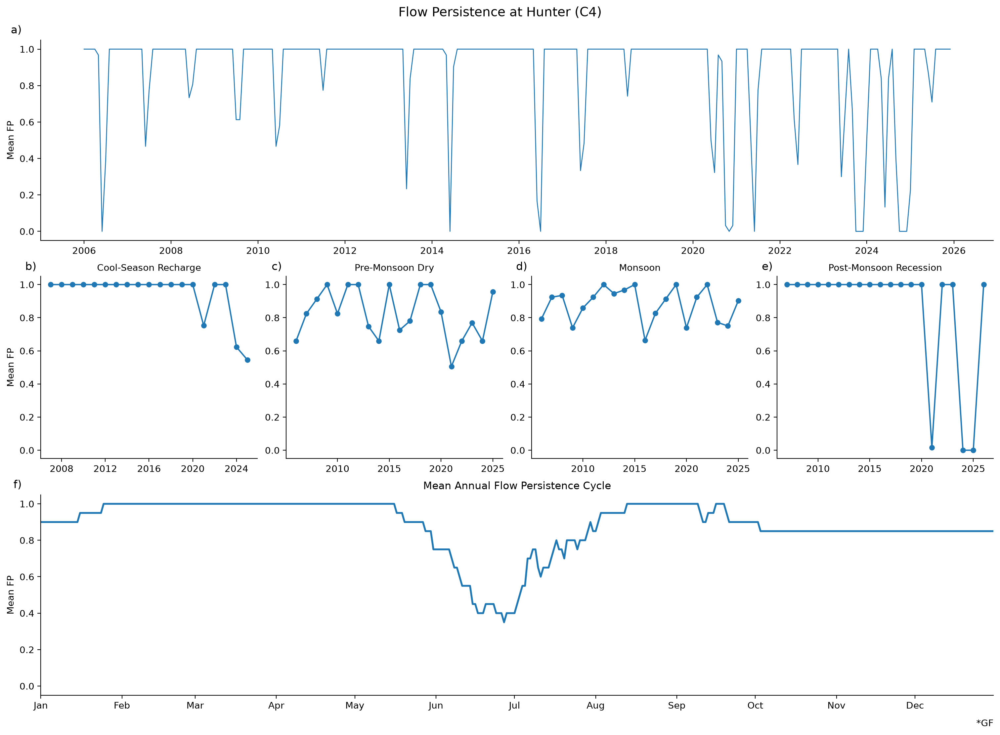

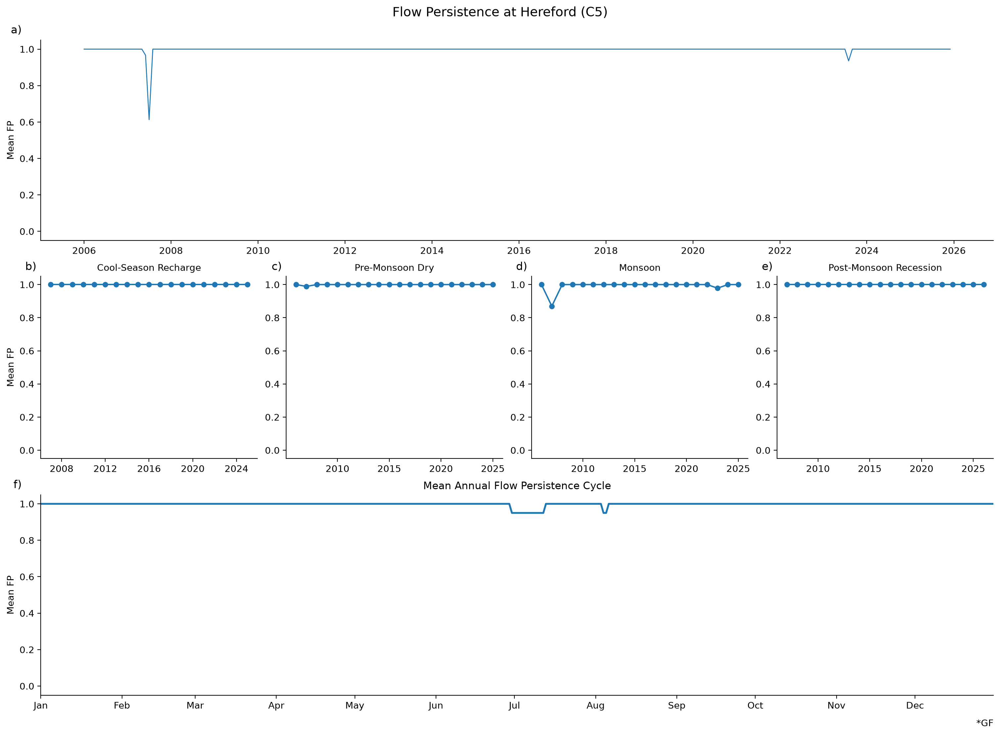

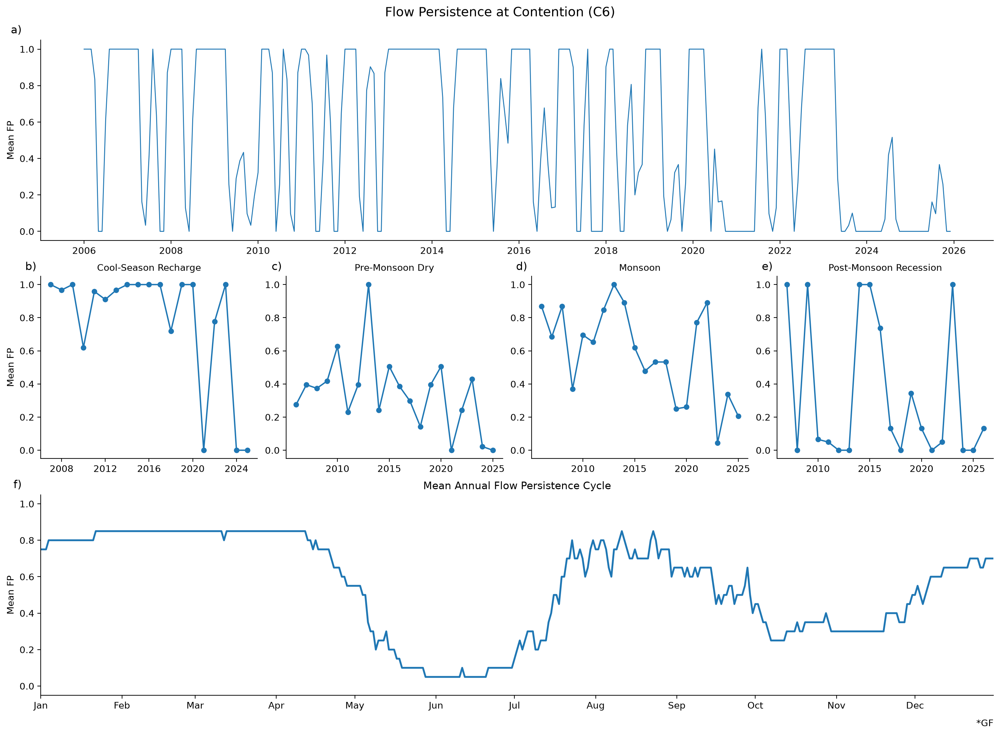

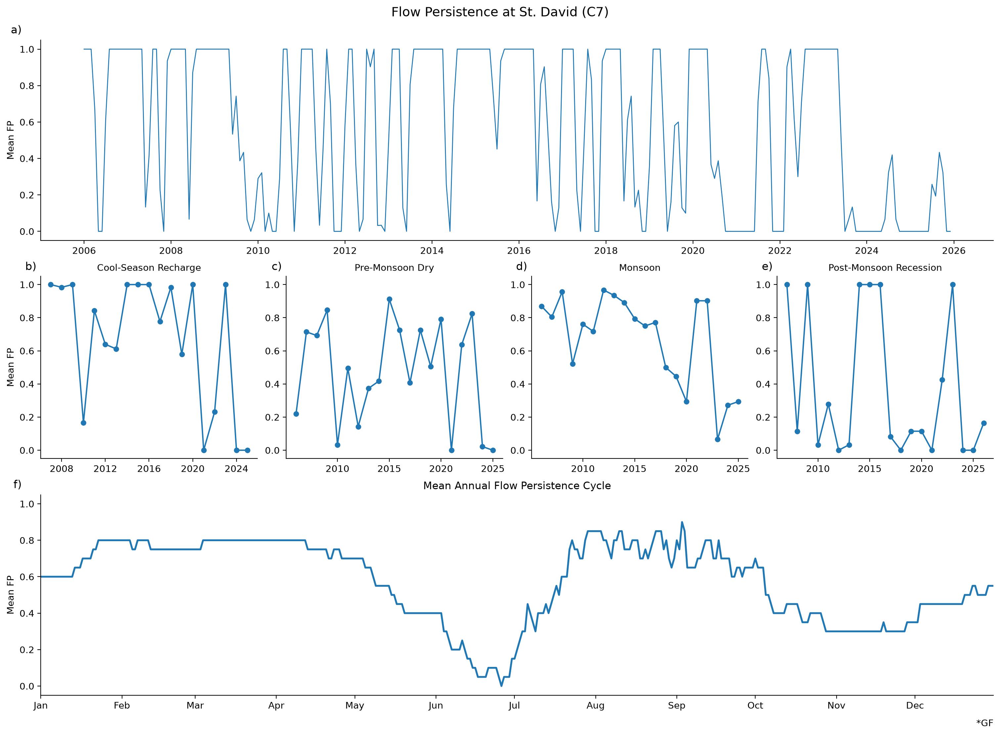

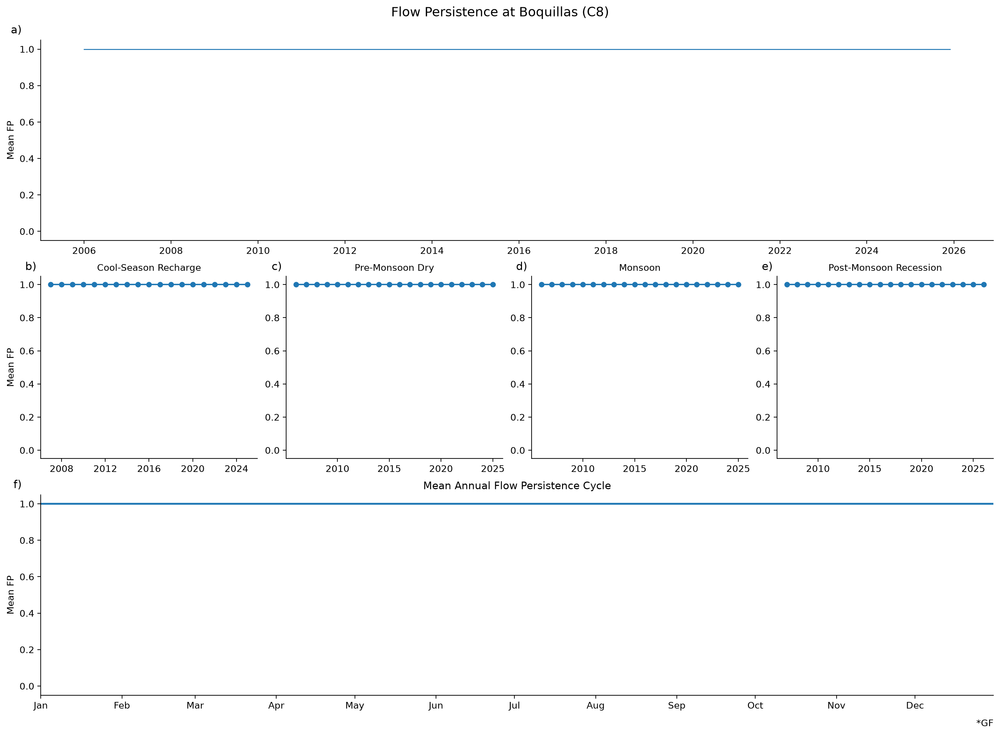

In [ ]:
fp_daily = (
    pd.read_csv(DATA / "SPRNCAPredFP.csv", parse_dates=["date"], usecols=["site", "date", "fp_final"])
    .rename(columns={"site": "Site"})
    .merge(cameras, on="Site", validate="many_to_one")
)
fp_daily["Water_Year"] = water_year(fp_daily["date"])
fp_daily["Season"] = season(fp_daily["date"])

fp_monthly = (
    fp_daily.groupby(["Camera", pd.Grouper(key="date", freq="MS")])["fp_final"]
    .mean().rename("fraction").reset_index()
)
fp_seasonal = (
    fp_daily.groupby(["Camera", "Water_Year", "Season"], as_index=False)["fp_final"]
    .agg(fraction="mean", n_days="size")
    .merge(season_lengths, on=["Water_Year", "Season"])
    .query("n_days == season_days")
)
fp_climatology = (
    fp_daily.assign(doy=lambda d: d["date"].dt.dayofyear)
    .query("doy <= 365")
    .groupby(["Camera", "doy"])["fp_final"]
    .mean().rename("fraction").reset_index()
    .assign(calendar_date=lambda d: pd.Timestamp("2001-01-01") + pd.to_timedelta(d["doy"] - 1, unit="D"))
)

def mark_gap_filled(axis):
    axis.text(1, -0.12, "*GF", transform=axis.transAxes, ha="right", va="top")

for camera in sorted(cameras["Camera"]):
    monthly = fp_monthly[fp_monthly["Camera"] == camera]
    seasonal = fp_seasonal[fp_seasonal["Camera"] == camera]
    climatology = fp_climatology[fp_climatology["Camera"] == camera]

    fig, axes = plt.subplot_mosaic(
        [["full"] * 4, SEASONS, ["clim"] * 4],
        figsize=(15, 11), height_ratios=[1.1, 1, 1.1], layout="constrained",
    )
    fig.suptitle(f"Flow Persistence at {site_label(camera)}", fontsize=14)

    axis = axes["full"]
    axis.plot(monthly["date"], monthly["fraction"], color=FP_COLOR, linewidth=1)
    axis.set_ylabel("Mean FP")
    axis.xaxis.set_major_locator(mdates.YearLocator(base=2))
    axis.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

    for season_code in SEASONS:
        axis = axes[season_code]
        data = seasonal[seasonal["Season"] == season_code]
        axis.plot(data["Water_Year"], data["fraction"], color=FP_COLOR, linewidth=1.5, marker="o", markersize=5)
        axis.set_title(SEASON_NAMES[season_code], fontsize=10)
        axis.xaxis.set_major_locator(plt.MaxNLocator(5, integer=True))
    axes["CSR"].set_ylabel("Mean FP")

    axis = axes["clim"]
    axis.plot(climatology["calendar_date"], climatology["fraction"], color=FP_COLOR, linewidth=2)
    axis.set_title("Mean Annual Flow Persistence Cycle", fontsize=11)
    axis.set_ylabel("Mean FP")
    axis.xaxis.set_major_locator(mdates.MonthLocator())
    axis.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    axis.set_xlim(pd.Timestamp("2001-01-01"), pd.Timestamp("2001-12-31"))
    mark_gap_filled(axis)

    for letter, key in zip("abcdef", ["full"] + SEASONS + ["clim"]):
        axes[key].set_ylim(-0.05, 1.05)
        style(axes[key])
        axes[key].text(-0.02, 1.02, f"{letter})", transform=axes[key].transAxes, ha="right", va="bottom", fontsize=12)

    plt.show()

%config InlineBackend.figure_format = "retina"